# Demo Text Analysis
## índice de incertidumbre de política monetaria 

**Datos:** 238 anuncios de política monetaria de Banxico, 2000–2026
(el comunicado que sale el día de cada decisión).

1. Cortar cada anuncio en pedazos de texto (chunks)
2. Pedirle a un LLM que califique cada pedazo de −2 (certeza) a +2 (incertidumbre)
3. Promediar los pedazos → un número por anuncio → un índice
4. Validarlo: ¿se mueve con la volatilidad del peso? ¿Sube en la crisis de 2008, el COVID, la elección de EUA de 2016?
5. Compararlo con dos métodos más simples: un diccionario de palabras y embeddings

> resultados ya guardados en disco pero celda llm es en vivo

In [1]:
# Preparación: librerías y rutas del proyecto (correr antes de la clase: la primera importación tarda)
import os
import sys
import time
from pathlib import Path

import numpy as np               
import pandas as pd                
import matplotlib.pyplot as plt   

# El código del proyecto vive en src/ (lógica) y scripts/ (la llamada al LLM);
# los agregamos a la ruta de Python para poder importarlos
sys.path.insert(0, str(Path.cwd().parent / "src"))
sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import paths
paths.add_src_subfolders_to_path()   # agrega las subcarpetas corpus/, index/ y analysis/

from common import rebuild_parent_chunks   # arma los pedazos de texto que lee el LLM
from llm_prompts import PROMPTS            # las instrucciones (prompts) que le damos al LLM
from sie import load_series_cached         # descarga series de Banxico (tipo de cambio)

P = paths.PROCESSED_DIR                    # carpeta con los datos ya procesados
pd.set_option("display.max_colwidth", 120) # mostrar más texto por celda en las tablas
# estilo de las gráficas: tamaño y sin bordes de arriba ni de la derecha
plt.rcParams.update({"figure.figsize": (12, 4.5), "axes.spines.top": False, "axes.spines.right": False})
print("listo")

listo


## 1. Los documentos

Así se ve un anuncio. Este es del **21 de abril de 2020**, en pleno COVID.

In [2]:
# Cargamos todos los anuncios de política monetaria (un renglón por anuncio, con su texto completo)
anuncios = pd.read_parquet(P / "banxico_anuncios_documents.parquet")
print(f"{len(anuncios)} anuncios, de {anuncios.publication_date.min():%Y} a {anuncios.publication_date.max():%Y}\n")

# Tomamos un ejemplo: el anuncio del 21 de abril de 2020 (plena pandemia)
ejemplo = anuncios.set_index("document_id").loc["banxico_apm_2020_04_21"]
print(ejemplo.title, "\n")
print(ejemplo.document_text[:1500], "...")   # solo los primeros 1,500 caracteres

238 anuncios, de 2000 a 2026

El objetivo para la Tasa de Interés Interbancaria a 1 día (tasa objetivo) disminuye en 50 puntos base 

21 de abril de 2020

Comunicado de Prensa

Anuncio de Política Monetaria

La Junta de Gobierno del Banco de México decidió disminuir en 50 puntos base el objetivo para 
la Tasa de Interés Interbancaria a un día a un nivel de 6%. También adoptó medidas adicionales 
para promover el funcionamiento ordenado de los mercados financieros, fortalecer los canales 
de otorgamiento de crédito y proveer liquidez para el sano desarrollo del sistema financiero. 
 
Ante la compleja situación económica y financiera global, el Banco de México ha seguido estrechamente 
el comportamiento de los mercados financieros nacionales, la actividad económica y la inflación, a fin 
de tomar las acciones necesarias de manera oportuna. La pandemia del COVID-19 y las medidas 
adoptadas para evitar su propagación han afectado considerablemente a la actividad económica 
mundial. Ello ha

## 2. Paso 1 — Cortar en pedazos (*chunks*)

Un anuncio mezcla temas: datos de inflación, riesgos, la decisión. Si lo calificamos
entero, todo se promedia. Así que lo cortamos en pedazos de unos 2,000 caracteres
(más o menos un par de párrafos) y calificamos cada uno por separado.

In [3]:
# El LLM no lee el anuncio completo: lo partimos en chunks de unos cuantos párrafos.
# rebuild_parent_chunks junta los pedazos pequeños guardados en disco en los pedazos que se califican.
pedazos = rebuild_parent_chunks(pd.read_parquet(P / "banxico_anuncios_chunks.parquet")).set_index("parent_chunk_id")
print(f"{len(pedazos)} pedazos en total, {len(pedazos) / len(anuncios):.1f} por anuncio en promedio\n")

# Mostramos los pedazos de nuestro anuncio de ejemplo (los primeros 400 caracteres de cada uno)
for pid, fila in pedazos[pedazos.document_id == "banxico_apm_2020_04_21"].iterrows():
    print(f"--- {pid}  ({len(fila.chunk_text)} caracteres)\n{fila.chunk_text[:400]} ...\n")

578 pedazos en total, 2.4 por anuncio en promedio

--- banxico_apm_2020_04_21_c0001  (2426 caracteres)
21 de abril de 2020 Comunicado de Prensa Anuncio de Política Monetaria La Junta de Gobierno del Banco de México decidió disminuir en 50 puntos base el objetivo para la Tasa de Interés Interbancaria a un día a un nivel de 6%. También adoptó medidas adicionales para promover el funcionamiento ordenado de los mercados financieros, fortalecer los canales de otorgamiento de crédito y proveer liquidez p ...

--- banxico_apm_2020_04_21_c0002  (2560 caracteres)
Se estima que las afectaciones sobre la actividad económica nacional derivadas de la pandemia, conducirían a una contracción importante de la actividad económica del país en el primer semestre del año. Si bien aún se desconocen la magnitud y duración de los efectos de la pandemia, y la información disponible aún es limitada, estimaciones iniciales sugieren que el PIB en el primer semestre de 2020  ...



## 3. Paso 2 — La rúbrica: el *prompt* es la metodología

Al LLM le damos instrucciones (el *prompt*) y un pedazo de texto. Nos responde
cuatro campos, en un formato fijo:

| campo | qué es |
|---|---|
| `relevant` | ¿el pedazo habla del panorama económico/monetario? (si no, no cuenta) |
| `uncertainty_score` | de −2 (mucha certeza) a +2 (mucha incertidumbre) |
| `confidence` | qué tan seguro está el modelo de su calificación |
| `evidence` | la frase del texto que justifica la calificación |

**La idea clave del prompt "calibrado":** Banxico habla de riesgos en *todos* sus
comunicados. Si cada mención de un riesgo contara como incertidumbre, el índice
diría "incierto" siempre. Así que le pedimos al modelo comparar contra
**cómo escribe Banxico normalmente**: el lenguaje rutinario de riesgos vale 0.

In [4]:
# El prompt "calibrado": las instrucciones exactas que recibe el LLM para calificar cada pedazo.
# Aquí está la metodología: qué cuenta como incertidumbre y qué significa cada calificación de −2 a +2.
PROMPT = PROMPTS["banxico_anuncios_calibrated"]
print(PROMPT)

You are an expert analyst of Banco de México's monetary-policy communication.
You classify short excerpts (chunks) from Banxico's monetary policy
announcements (comunicados de política monetaria), the statement published on
the day of each policy decision, for a Monetary Policy Uncertainty (MPU) index.

YOUR TASK
Measure how much uncertainty about the macroeconomic and monetary-policy
outlook the excerpt conveys: inflation, the policy/interest-rate path, growth,
the exchange rate, external conditions, and the balance of risks.

CALIBRATE TO BANXICO'S NORMAL LANGUAGE
Banxico's statements discuss risks in almost every paragraph. A list of the
risks to inflation and growth, and a sentence on whether the balance of risks
is biased up or down, appear in nearly every statement, whether conditions are
calm or turbulent. That routine language is the baseline and scores 0.
Score above 0 only when the excerpt conveys MORE uncertainty than a typical
Banxico statement: uncertainty that is named, e

## 4. En vivo calificar un pedazo

Le mandamos al modelo (GPT-6.1 Sol, vía OpenRouter) el segundo pedazo del anuncio de abril de 2020.
Es **exactamente el mismo código** que calificó los 578 pedazos del corpus.

In [5]:
# LLAMADA EN VIVO: le mandamos un pedazo del anuncio de abril 2020 al modelo y vemos qué responde
PEDAZO = "banxico_apm_2020_04_21_c0002"
texto = pedazos.loc[PEDAZO, "chunk_text"]

try:
    import httpx         # librería para hacer solicitudes por internet
    import score_chunks_openrouter as sco     # el script del pipeline (lee la llave de .env)
    sco.REQUEST_DEADLINE_SECONDS = 30       #para no esperar más de 30 segundos

    # cliente que se conecta a OpenRouter con nuestra llave 
    cliente = httpx.Client(timeout=30, headers={"Authorization": f"Bearer {os.environ['OPEN_ROUTER_KEY']}"})
    # armamos la solicitud: modelo + prompt + texto del pedazo, con razonamiento mínimo
    solicitud = sco.build_request("openai/gpt-6.1-sol", PROMPT, texto,
                                  reasoning_effort="minimal", use_temperature=False)
    inicio = time.time()
    respuesta = sco.score_one(cliente, solicitud, attempts=2)   # la enviamos (hasta 2 intentos)

    if respuesta["error"]:
        print("ERROR: la llamada falló:", respuesta["error"][:200], "\n→ correr la celda de respaldo")
    else:
        print(f"Respuesta en {time.time() - inicio:.1f} s, costo ${respuesta['cost_usd']:.4f} dólares\n")
        # lo que devuelve el modelo: ¿es relevante?, calificación (−2 a +2), confianza y la frase que lo justifica
        for campo in ["relevant", "uncertainty_score", "confidence", "evidence"]:
            print(f"{campo:18s} {respuesta[campo]}")
except Exception as e:
    # si no hay internet o falta la llave, no se rompe la demo: usamos la celda de respaldo
    print(f"ERROR: sin conexión o sin llave ({type(e).__name__}) → correr la celda de respaldo")

ERROR: sin conexión o sin llave (KeyError) → correr la celda de respaldo


In [6]:
# LLAMADA EN VIVO: le mandamos un pedazo del anuncio de abril 2020 al modelo y vemos qué responde
PEDAZO = "banxico_apm_2020_04_21_c0001"
texto = pedazos.loc[PEDAZO, "chunk_text"]

try:
    import httpx         # librería para hacer solicitudes por internet
    import score_chunks_openrouter as sco     # el script del pipeline (lee la llave de .env)
    sco.REQUEST_DEADLINE_SECONDS = 30       #para no esperar más de 30 segundos

    # cliente que se conecta a OpenRouter con nuestra llave 
    cliente = httpx.Client(timeout=30, headers={"Authorization": f"Bearer {os.environ['OPEN_ROUTER_KEY']}"})
    # armamos la solicitud: modelo + prompt + texto del pedazo, con razonamiento mínimo
    solicitud = sco.build_request("openai/gpt-6.1-sol", PROMPT, texto,
                                  reasoning_effort="minimal", use_temperature=False)
    inicio = time.time()
    respuesta = sco.score_one(cliente, solicitud, attempts=2)   # la enviamos (hasta 2 intentos)

    if respuesta["error"]:
        print("ERROR: la llamada falló:", respuesta["error"][:200], "\n→ correr la celda de respaldo")
    else:
        print(f"Respuesta en {time.time() - inicio:.1f} s, costo ${respuesta['cost_usd']:.4f} dólares\n")
        # lo que devuelve el modelo: ¿es relevante?, calificación (−2 a +2), confianza y la frase que lo justifica
        for campo in ["relevant", "uncertainty_score", "confidence", "evidence"]:
            print(f"{campo:18s} {respuesta[campo]}")
except Exception as e:
    # si no hay internet o falta la llave, no se rompe la demo: usamos la celda de respaldo
    print(f"ERROR: sin conexión o sin llave ({type(e).__name__}) → correr la celda de respaldo")

ERROR: sin conexión o sin llave (KeyError) → correr la celda de respaldo


**Respaldo** — si no hay internet: la respuesta que el modelo dio a este mismo pedazo
cuando corrimos el corpus completo.

In [7]:
# RESPALDO: la calificación que el mismo modelo le dio a este pedazo cuando corrimos todo el corpus
# (guardada en disco, así que no necesita internet)
guardado = pd.read_parquet(P / "llm_scores" / "banxico_anuncios__calibrated__openai_gpt-6.1-sol.parquet").set_index("parent_chunk_id")
for campo in ["relevant", "uncertainty_score", "confidence", "evidence"]:
    print(f"{campo:18s} {guardado.loc[PEDAZO, campo]}")

relevant           True
uncertainty_score  2.0
confidence         0.9
evidence           Ello ha dado lugar a importantes revisiones de las expectativas económicas, las cuales incorporan una fuerte contracción de la actividad productiva


## 5. Paso 3 — pasar de chunks a promedio por documento
El índice de un anuncio es **el promedio de las calificaciones de sus pedazos relevantes**.
Comparemos el anuncio de febrero de 2020 (antes del COVID) con el de abril:

In [8]:
# De pedazos a documento: el índice de un anuncio es el PROMEDIO de las calificaciones de sus pedazos
def calificaciones(document_id):
    # todas las calificaciones de un anuncio con la evidencia que citó el modelo
    filas = guardado[guardado.document_id == document_id]
    return filas[["uncertainty_score", "evidence"]]

# Comparamos un anuncio antes de la pandemia (febrero 2020) con uno durante (abril 2020)
for doc in ["banxico_apm_2020_02_13", "banxico_apm_2020_04_21"]:
    t = calificaciones(doc)
    print(f"=== {doc[-10:]}   →   índice del anuncio = {t.uncertainty_score.mean():.1f}")
    display(t)

=== 2020_02_13   →   índice del anuncio = 0.5


,uncertainty_score,evidence
parent_chunk_id,,
banxico_apm_2020_02_13_c0001,1.0,se mantiene incertidumbre en cuanto al balance de riesgos para la trayectoria descrita de la inflación.
banxico_apm_2020_02_13_c0002,0.0,decidió por unanimidad disminuir en 25 puntos base el objetivo para la Tasa de Interés Interbancaria a un día a un n...


=== 2020_04_21   →   índice del anuncio = 2.0


,uncertainty_score,evidence
parent_chunk_id,,
banxico_apm_2020_04_21_c0001,2.0,"Ello ha dado lugar a importantes revisiones de las expectativas económicas, las cuales incorporan una fuerte contrac..."
banxico_apm_2020_04_21_c0002,2.0,la incertidumbre sobre el balance de riesgos para la inflación se ha acentuado significativamente.


Hacemos esto para los 238 anuncios y obtenemos una serie de tiempo. Las zonas
sombreadas son episodios que **fijamos antes de ver los resultados** (para no hacer trampa).
La línea punteada en 2008 marca el cambio de instrumento (del "corto" a la tasa objetivo):
antes de eso los anuncios eran más cortos y distintos, así que esa parte se compara con cautela.

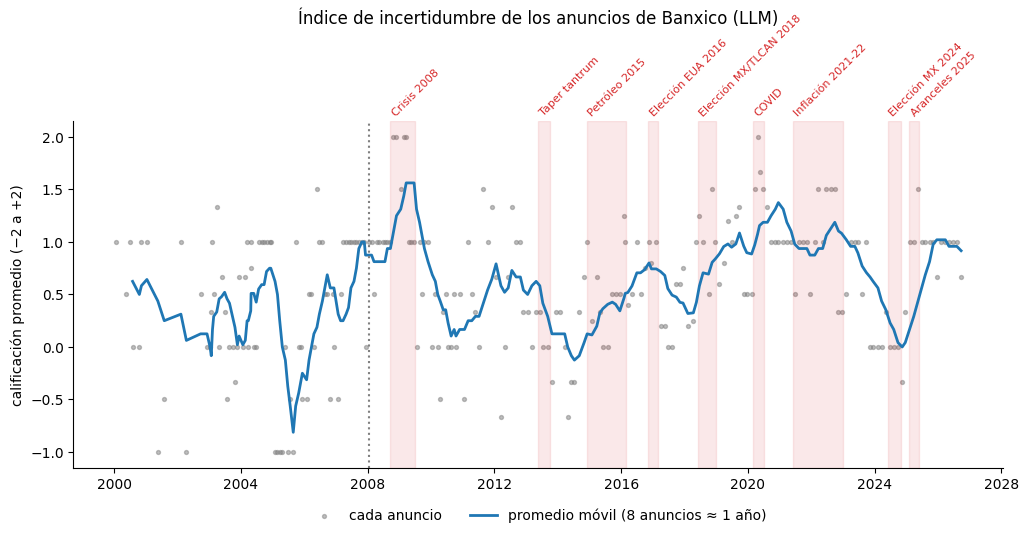

In [9]:
# El índice ya calculado: un valor por anuncio, para las 4 versiones (2 prompts × 2 modelos)
indice = pd.read_parquet(P / "banxico_anuncios_index_llm.parquet").sort_values("publication_date").reset_index(drop=True)
indice["fecha"] = indice.publication_date
PRINCIPAL = "mpu_llm_calibrated_gpt_6_1_sol"          # versión principal: prompt calibrado + GPT-6.1 Sol

# Episodios de incertidumbre conocidos, fijados ANTES de ver los resultados (para no hacer trampa)
EPISODIOS = {
    "Crisis 2008":           ("2008-09-15", "2009-06-30"),
    "Taper tantrum":         ("2013-05-22", "2013-09-30"),
    "Petróleo 2015":         ("2014-12-01", "2016-02-29"),
    "Elección EUA 2016":     ("2016-11-08", "2017-02-28"),
    "Elección MX/TLCAN 2018": ("2018-06-01", "2018-12-31"),
    "COVID":                 ("2020-03-01", "2020-06-30"),
    "Inflación 2021-22":     ("2021-06-01", "2022-12-31"),
    "Elección MX 2024":      ("2024-06-01", "2024-10-31"),
    "Aranceles 2025":        ("2025-02-01", "2025-05-31"),
}

def sombrear(ax, etiquetas=True):
    # episodios sombreados, con el nombre arriba de la gráfica
    for nombre, (a, b) in EPISODIOS.items():
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="tab:red", alpha=0.10)
        if etiquetas:
            ax.text(pd.Timestamp(a), 1.01, nombre, transform=ax.get_xaxis_transform(),
                    rotation=45, ha="left", va="bottom", fontsize=8, color="tab:red")

# Gráfica: cada punto es un anuncio; la línea es el promedio móvil (cada anuncio solo es ruidoso)
fig, ax = plt.subplots()
ax.scatter(indice.fecha, indice[PRINCIPAL], s=8, color="gray", alpha=0.5, label="cada anuncio")
ax.plot(indice.fecha, indice[PRINCIPAL].rolling(8, min_periods=4).mean(), lw=2, label="promedio móvil (8 anuncios ≈ 1 año)")
ax.set_ylabel("calificación promedio (−2 a +2)")
ax.axvline(pd.Timestamp("2008-01-21"), color="gray", ls=":")   # Banxico pasa del "corto" a la tasa objetivo
ax.set_title("Índice de incertidumbre de los anuncios de Banxico (LLM)", pad=70)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, frameon=False)
sombrear(ax)
plt.show()

## 6. ¿Importa el prompt? Calibrado vs. relajado

Corrimos también un prompt **relajado**: solo la pregunta, sin calibración ni ejemplos
("usa tu propio juicio"). ¿Cómo usa cada uno la escala?

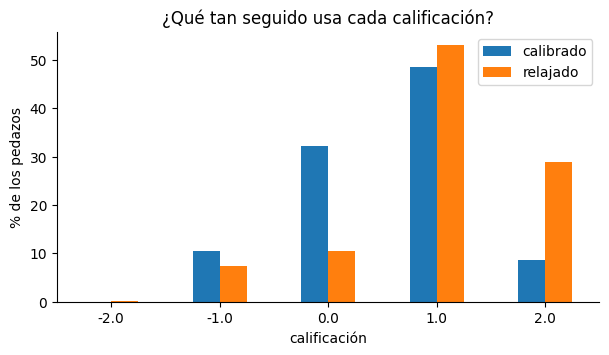

,calibrado,relajado
uncertainty_score,,
-2.0,0.0,0.0
-1.0,11.0,7.0
0.0,32.0,10.0
1.0,49.0,53.0
2.0,9.0,29.0


In [10]:
# ¿Importa el prompt? Comparamos las calificaciones del prompt calibrado vs. el relajado (mismo modelo)
relajado = pd.read_parquet(P / "llm_scores" / "banxico_anuncios__lax__openai_gpt-6.1-sol.parquet")
# porcentaje de pedazos que recibe cada calificación (−2, −1, 0, +1, +2) con cada prompt
dist = pd.DataFrame({
    "calibrado": guardado.uncertainty_score.value_counts(normalize=True),
    "relajado":  relajado.uncertainty_score.value_counts(normalize=True),
}).sort_index().fillna(0) * 100

dist.plot.bar(figsize=(7, 3.5), rot=0)
plt.ylabel("% de los pedazos"); plt.xlabel("calificación"); plt.title("¿Qué tan seguido usa cada calificación?")
plt.show()
dist.round(0)

El prompt relajado casi nunca da 0: para él, *mencionar un riesgo* ya es incertidumbre.
El calibrado reserva el +2 para cuando de verdad importa. Ejemplo — junio de 2024,
una lista estándar de riesgos:

In [11]:
# Un ejemplo donde los dos prompts no coinciden: lenguaje rutinario de riesgos (junio 2024)
pid = "banxico_apm_2024_06_27_c0001"
r = relajado.set_index("parent_chunk_id")
print(pedazos.loc[pid, "chunk_text"][:700], "...\n")
print(f"calibrado: {guardado.loc[pid, 'uncertainty_score']:+.0f}     relajado: {r.loc[pid, 'uncertainty_score']:+.0f}")

27 de junio de 2024 Comunicado de Prensa Anuncio de Política Monetaria La Junta de Gobierno del Banco de México decidió mantener el objetivo para la Tasa de Interés Interbancaria a un día en 11.00%. Se prevé que la actividad económica global continúe expandiéndose en el segundo trimestre de 2024, aunque a un ritmo menor que el trimestre anterior. En la mayoría de las economías avanzadas, la inflación general y la subyacente continuaron disminuyendo. La Reserva Federal mantuvo sin cambio la tasa de fondos federales, mientras que algunos bancos centrales de economías avanzadas realizaron recortes en sus tasas de referencia. Los mercados financieros internacionales exhibieron movimientos acotad ...

calibrado: +0     relajado: +1


**Comparando modelos** Corrimos 2 prompts × 2 modelos (uno barato, GPT-6 Luna, y uno caro, GPT-6.1 Sol).
Las cuatro versiones del índice se parecen bastante:

In [12]:
# misma historia las 4 versiones - correlación (8 anuncios)
versiones = {"mpu_llm_calibrated_gpt_6_1_sol": "calibrado·Sol", "mpu_llm_calibrated_gpt_6_luna": "calibrado·Luna",
             "mpu_llm_lax_gpt_6_1_sol": "relajado·Sol", "mpu_llm_lax_gpt_6_luna": "relajado·Luna"}
indice[list(versiones)].rolling(8, min_periods=8).mean().corr().rename(index=versiones, columns=versiones).round(2)

,calibrado·Sol,calibrado·Luna,relajado·Sol,relajado·Luna
calibrado·Sol,1.00,0.91,0.70,0.85
calibrado·Luna,0.91,1.00,0.79,0.93
relajado·Sol,0.70,0.79,1.00,0.87
relajado·Luna,0.85,0.93,0.87,1.00


Las cuatro versiones, en **anuncios y minutas** (estandarizadas: 0 = nivel típico, unidades = desviaciones estándar):

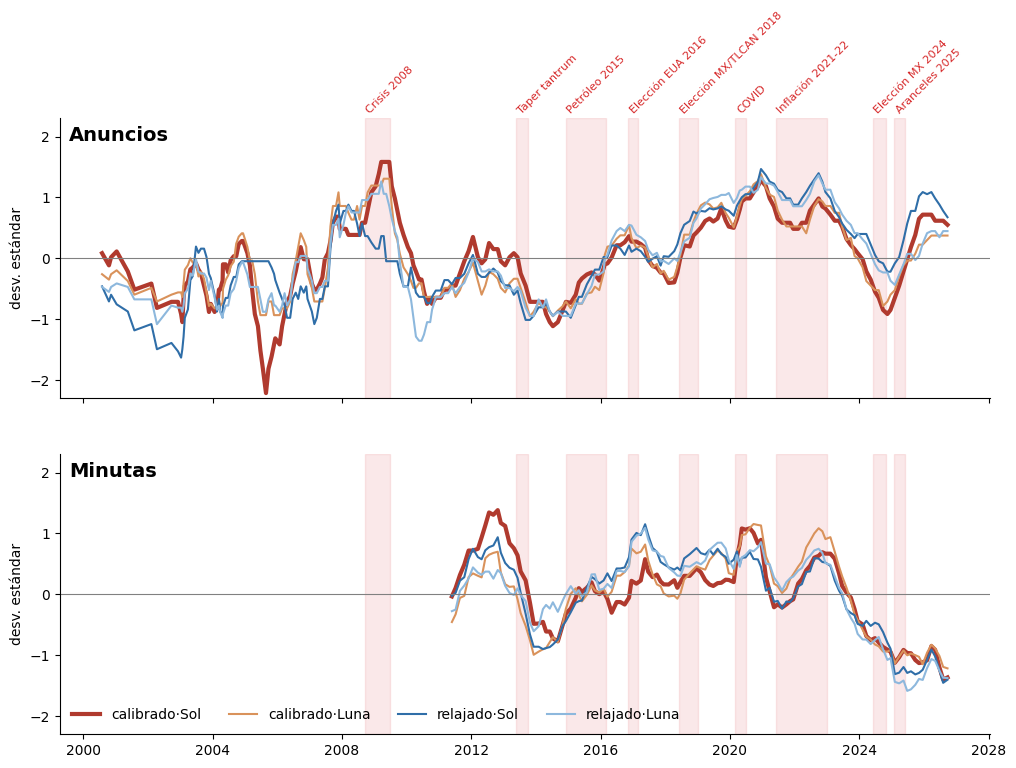

In [13]:
# Las 4 versiones en el tiempo, para anuncios (arriba) y minutas (abajo)
minutas = pd.read_parquet(P / "banxico_minutas_index_llm.parquet")
minutas["fecha"] = pd.to_datetime(minutas.decision_date)       # las minutas se fechan por la decisión
minutas = minutas.sort_values("fecha").reset_index(drop=True)

# estandarizar = restar el promedio y dividir entre la desviación estándar,
# para poner todas las versiones en la misma escala
z = lambda serie: (serie - serie.mean()) / serie.std()
# color y grosor de línea de cada versión (la principal más gruesa)
COLORES = {"mpu_llm_calibrated_gpt_6_1_sol": ("#B03A2E", 3), "mpu_llm_calibrated_gpt_6_luna": ("#D9925B", 1.5),
           "mpu_llm_lax_gpt_6_1_sol": ("#2F6EA8", 1.5), "mpu_llm_lax_gpt_6_luna": ("#8DB8DD", 1.5)}

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)   # dos paneles con el mismo eje de fechas
for ax, datos, nombre in [(axes[0], indice, "Anuncios"), (axes[1], minutas, "Minutas")]:
    for col, (color, grosor) in COLORES.items():
        # cada versión estandarizada y suavizada con 8 documentos
        ax.plot(datos.fecha, z(datos[col]).rolling(8, min_periods=4).mean(), color=color, lw=grosor, label=versiones[col])
    ax.axhline(0, color="gray", lw=0.8); ax.set_ylabel("desv. estándar"); ax.set_ylim(-2.3, 2.3)
    ax.text(0.01, 0.92, nombre, transform=ax.transAxes, fontsize=14, fontweight="bold")
    sombrear(ax, etiquetas=(ax is axes[0]))   # nombres de episodios solo en el panel de arriba
axes[1].legend(loc="lower left", ncol=4, frameon=False)
plt.show()

## 7. Validación externa: volatilidad del peso

**volatilidad del tipo de cambio** (desviación estándar de los rendimientos diarios
del FIX, anualizada) en los 30 días antes de cada decisión.

volatilidad típica del peso: 8.3% anual


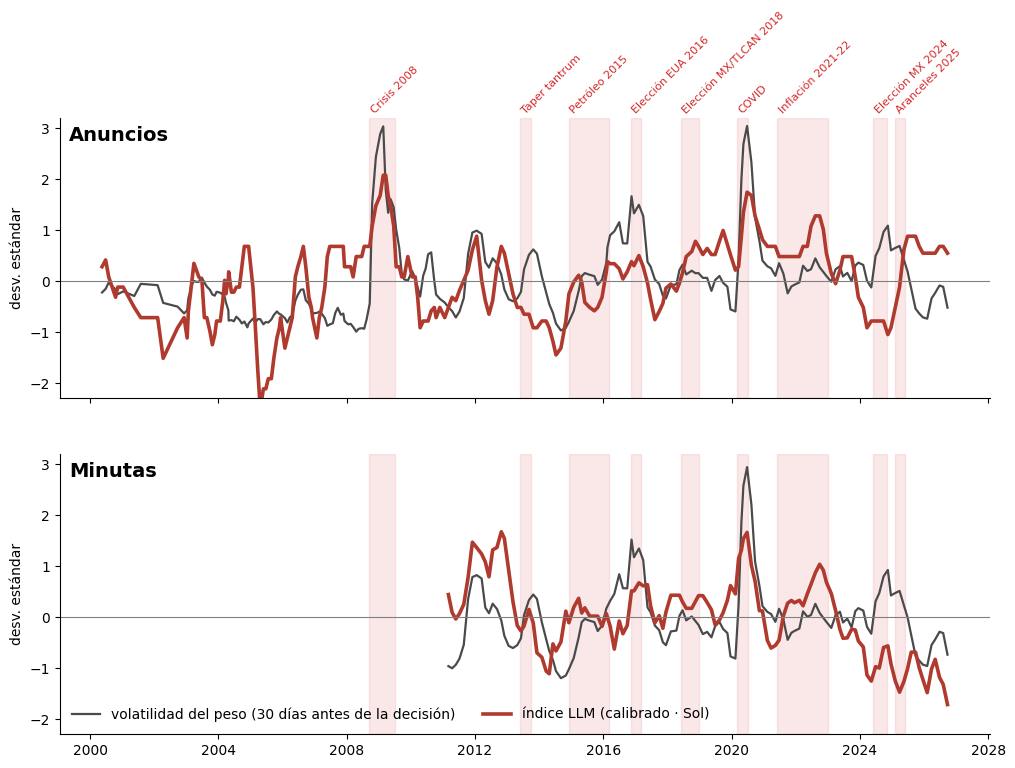

correlación documento por documento, anuncios: 0.37
correlación documento por documento, minutas: 0.37


In [14]:
# VALIDACIÓN: ¿el índice sube cuando el mercado también está nervioso?
# Usamos la volatilidad del peso (tipo de cambio FIX) como referencia externa
fix = load_series_cached("exchange_rate", P).set_index("date")["value"].sort_index()
rend = np.log(fix).diff().dropna()          # rendimientos diarios: cambio porcentual del tipo de cambio

def volatilidad_antes(fecha, dias=30):
    # desviación estándar de los rendimientos en los 30 días previos a la decisión,
    # anualizada (× raíz de 252 días hábiles) y en porcentaje
    r = rend[(rend.index > fecha - pd.Timedelta(days=dias)) & (rend.index <= fecha)]
    return r.std() * np.sqrt(252) * 100 if len(r) >= 10 else np.nan   # pedimos al menos 10 días de datos

# una volatilidad por documento, para anuncios y para minutas
indice["vol_peso"] = indice.fecha.apply(volatilidad_antes)
print(f"volatilidad típica del peso: {indice.vol_peso.median():.1f}% anual")

minutas["vol_peso"] = minutas.fecha.apply(volatilidad_antes)

# las dos series estandarizadas y suavizadas con 4 documentos
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, datos, nombre in [(axes[0], indice, "Anuncios"), (axes[1], minutas, "Minutas")]:
    ax.plot(datos.fecha, z(datos.vol_peso).rolling(4, min_periods=2).mean(), color="#4A4A4A", lw=1.6,
            label="volatilidad del peso (30 días antes de la decisión)")
    ax.plot(datos.fecha, z(datos[PRINCIPAL]).rolling(4, min_periods=2).mean(), color="#B03A2E", lw=2.6,
            label="índice LLM (calibrado · Sol)")
    ax.axhline(0, color="gray", lw=0.8); ax.set_ylabel("desv. estándar"); ax.set_ylim(-2.3, 3.2)
    ax.text(0.01, 0.92, nombre, transform=ax.transAxes, fontsize=14, fontweight="bold")
    sombrear(ax, etiquetas=(ax is axes[0]))
axes[1].legend(loc="lower left", ncol=2, frameon=False)
plt.show()

# correlación sin suavizar: cada documento contra la volatilidad del peso en su fecha
for nombre, datos in [("anuncios", indice), ("minutas", minutas)]:
    print(f"correlación documento por documento, {nombre}: {datos[PRINCIPAL].corr(datos.vol_peso):.2f}")

### Episodio por episodio

Percentil promedio dentro de cada episodio (50 = normal, 100 = el más alto de toda la historia).

In [15]:
# ¿Qué tan alto queda cada episodio? Percentil promedio de sus anuncios
# (percentil 50 = un anuncio típico; 90 = de los más altos de toda la muestra)
pct = indice[[PRINCIPAL, "vol_peso"]].rank(pct=True) * 100
filas = []
for nombre, (a, b) in EPISODIOS.items():
    m = indice.fecha.between(a, b)          # anuncios que caen dentro del episodio
    filas.append({"episodio": nombre, "anuncios": int(m.sum()),
                  "índice LLM (percentil)": round(pct.loc[m, PRINCIPAL].mean()),
                  "vol. del peso (percentil)": round(pct.loc[m, "vol_peso"].mean())})
pd.DataFrame(filas).set_index("episodio")

,anuncios,índice LLM (percentil),vol. del peso (percentil)
episodio,,,
Crisis 2008,9,87,92
Taper tantrum,3,24,82
Petróleo 2015,11,47,67
Elección EUA 2016,3,67,85
Elección MX/TLCAN 2018,5,75,68
COVID,4,97,97
Inflación 2021-22,13,69,62
Elección MX 2024,3,19,88
Aranceles 2025,3,80,74



- **Crisis 2008 y COVID:** el índice y el peso se disparan juntos. El anuncio del 17 de oct. de 2008 y el de abril de 2020 tienen la calificación máxima.
- **Aranceles 2025:** el índice sube (en las minutas, en cambio, no se ve; las minutas se volvieron mucho más largas y el promedio se diluye).
- **Elección EUA 2016:** sube algo en los anuncios; en las minutas se ve mucho más claro (percentil 87).
- **Inflación 2021–22:** el índice sube y el peso está tranquilo. No es un error: la incertidumbre era sobre la *inflación*, no sobre el tipo de cambio.
- **Taper tantrum 2013 y elección de México 2024:** el peso se movió mucho pero Banxico escribió con calma (y no comenta la política interna). **El índice solo puede medir lo que el banco dice.**

## 8. Comparando los tres métodos 

Construimos el índice de tres formas independientes:

| | cómo funciona | analogía |
|---|---|---|
| **M1 diccionario** | cuenta palabras de incertidumbre cerca de palabras de un tema, por cada 1,000 palabras | un buscador de palabras clave |
| **M2 embeddings** | convierte cada pedazo en un vector y mide qué tan cerca está de frases "inciertas" vs. "seguras" | medir parecido de significado |
| **M3 LLM** | un modelo *lee* el pedazo y lo califica con una rúbrica | un analista que lee |

In [16]:
# LOS TRES MÉTODOS: cargamos el índice de diccionario (M1) y el de embeddings (M2) y los unimos al del LLM (M3)
m1 = pd.read_parquet(P / "banxico_anuncios_index_exact_matching.parquet")[["document_id", "unc_rate_policy"]]
m2 = pd.read_parquet(P / "banxico_anuncios_index_embeddings.parquet")[["document_id", "mpu_embed"]]
tres = indice.merge(m1, on="document_id").merge(m2, on="document_id")   # una tabla con los tres por anuncio
METODOS = {"unc_rate_policy": "M1 diccionario", "mpu_embed": "M2 embeddings", PRINCIPAL: "M3 LLM"}

# trimestral, 6 trimestres
trim = tres.set_index("fecha")[list(METODOS)].resample("QE").mean()      # promedio de los anuncios de cada trimestre
vol_trim = (rend.resample("QE").std() * np.sqrt(252)).rename("vol")      # volatilidad del peso de cada trimestre
filas = []
for col, nombre in METODOS.items():
    con_dato = trim[col].dropna().index     # trimestres con al menos un anuncio
    # promedio móvil de 6 trimestres de índice y volatilidad, alineados por trimestre
    s = pd.concat([trim[col].rolling(6, min_periods=1).mean(),
                   vol_trim.rolling(6, min_periods=1).mean()], axis=1, join="inner").loc[con_dato].dropna()
    # dos correlaciones con el peso: anuncio por anuncio (ruidosa) y trimestral suavizada
    filas.append({"método": nombre, "por anuncio": round(tres[col].corr(tres.vol_peso), 2),
                  "trimestral suavizado": round(s[col].corr(s.vol), 2)})
pd.DataFrame(filas).set_index("método")

,por anuncio,trimestral suavizado
método,,
M1 diccionario,0.11,0.36
M2 embeddings,0.33,0.53
M3 LLM,0.37,0.57


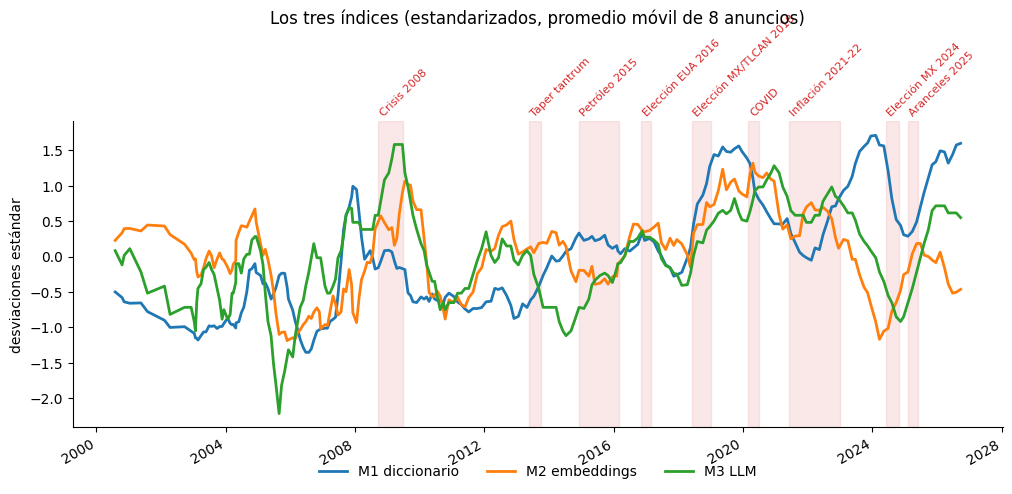

In [17]:
# tres índices juntos en una gráfica: estandarizados para compararlos en la misma escala
z = (tres.set_index("fecha")[list(METODOS)] - tres[list(METODOS)].mean().values) / tres[list(METODOS)].std().values
# promedio móvil de 8 anuncios (≈ 1 año) para ver la tendencia y no el ruido
ax = z.rolling(8, min_periods=4).mean().rename(columns=METODOS).plot(lw=2, xlabel="")
ax.set_ylabel("desviaciones estándar"); ax.set_title("Los tres índices (estandarizados, promedio móvil de 8 anuncios)", pad=70)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
sombrear(ax)
plt.show()

**En los anuncios, el LLM y los embeddings quedan cerca, y el diccionario muy atrás.** El diccionario
—que era el mejor en los Informes Trimestrales— casi no funciona aquí: sus listas de palabras se hicieron
para otro tipo de documento. El LLM no necesitó ningún ajuste para el documento nuevo.

Pero en los **Informes Trimestrales** (otro corpus, contra tres referencias distintas) el resultado fue:

| | vol. del peso | dispersión de pronósticos de inflación | episodios |
|---|---|---|---|
| M1 diccionario | **mejor** (+0.52) | negativa | la más débil |
| M2 embeddings | débil (+0.18) | **mejor** (+0.56) | intermedia |
| M3 LLM | +0.43 | +0.18 | **mejor** |

### Ningún método gana en todo.
"¿Cuál es mejor?" no tiene respuesta independiente de **qué quieres que signifique el índice**.

## 9. Conclusiones

1. **El texto de un banco central sí contiene información medible sobre incertidumbre**: el índice sube en 2008 y en el COVID, igual que el peso.
2. **El prompt es la metodología.** Calibrar contra el lenguaje normal de Banxico hace que el índice marque incertidumbre *cuando importa*, no siempre.
3. **El LLM se adapta a documentos nuevos sin reajustarlo**; el diccionario no.
4. **El índice mide lo que el banco dice, no lo que pasa**: si Banxico escribe con calma (2013, 2024), el índice no lo ve.
5. **Escogimos la versión principal antes de ver los resultados**, para no elegir la que "salió mejor".

**Pendientes:** cómo combinar los pedazos (el promedio diluye los votos divididos en las minutas),
etiquetas humanas de la calificación, y una segunda referencia (dispersión de pronósticos de inflación).

**Costo total (anuncios y minutas, unos 2,700 pedazos, 4 versiones, más las pruebas piloto): unos $15 dólares.**